<a href="https://colab.research.google.com/github/tlh222k/ai-from-scratch/blob/main/phases/00-math-foundations/calculus/01-calculus-fundamentals-for-machine-learning/chapter-5-calculus-in-action-simple-optimization/08-hands-on-practicalmanual-gradient-calculation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Thực hành: Tính toán Gradient bằng phương pháp thủ công (Hands-on Practical: Manual Gradient Calculation)**

Các **Hàm chi phí (Cost Functions)**, **Gradient** và ý tưởng cơ bản của **Tối ưu hóa xuống dốc (Gradient Descent)** là những khái niệm thiết yếu trong tối ưu hóa **Học máy (Machine Learning)**. Việc tính toán Gradient bằng tay cho một mô hình hồi quy tuyến tính đơn giản, sử dụng một tập dữ liệu nhỏ, mang lại những hiểu biết thực tiễn. Quá trình này giúp củng cố sự hiểu việc cách các đạo hàm thúc đẩy quá trình tối ưu hóa.

## **1. Thiết lập bài toán: Một vấn đề đơn giản (Setting the Scene: A Simple Problem)**

Hãy tưởng tượng chúng ta có một tập dữ liệu rất nhỏ, chỉ gồm ba điểm $(x,y)$: $(1,2)$, $(2,3)$ và $(3,5)$. Mục tiêu của chúng ta là tìm đường thẳng khớp tốt nhất với các điểm này, có dạng:

$$
y=mx+b
$$

Tập dữ liệu nhỏ của chúng ta gồm ba điểm, cùng với một dự đoán ban đầu cho đường thẳng:

$$
y=0x+0
$$

Chúng ta cần một phương pháp để đo lường mức độ “tốt” của đường thẳng. Chúng ta sẽ sử dụng **Bình phương sai số trung bình (Mean Squared Error - MSE)** làm *Cost Function*, như đã thảo luận trước đó. Với ba điểm dữ liệu $(x_1,y_1)$, $(x_2,y_2)$, $(x_3,y_3)$, *MSE* được tính như sau:

$$
J(m,b)=\frac{1}{3}\sum_{i=1}^{3}(y_i-\hat{y}_i)^2
=\frac{1}{3}\sum_{i=1}^{3}(y_i-(mx_i+b))^2
$$

Hãy bắt đầu với dự đoán ban đầu cho các tham số: $m=0$ và $b=0$. Khi đó, đường thẳng ban đầu của chúng ta là $y=0$.

## **2. Tính toán chi phí ban đầu (Calculating the Initial Cost)**

Trước tiên, hãy tính chi phí cho dự đoán ban đầu $(m=0,b=0)$. Các giá trị dự đoán $\hat{y}_i=mx_i+b$ là:

$$
\hat{y}_1=0(1)+0=0
$$

$$
\hat{y}_2=0(2)+0=0
$$

$$
\hat{y}_3=0(3)+0=0
$$

Các sai số bình phương là:

$$
(y_1-\hat{y}_1)^2=(2-0)^2=4
$$

$$
(y_2-\hat{y}_2)^2=(3-0)^2=9
$$

$$
(y_3-\hat{y}_3)^2=(5-0)^2=25
$$

*MSE* là:

$$
J(0,0)=\frac{1}{3}(4+9+25)=\frac{38}{3}\approx12.67
$$

Đây là chi phí ban đầu của chúng ta. Mục tiêu là giảm giá trị này bằng cách điều chỉnh $m$ và $b$.

## **3. Tính toán toán học cho Gradient (Mathematical Gradient Derivation)**

Bây giờ là phần cốt lõi liên quan đến giải tích: tìm Gradient của *Cost Function* $J(m,b)$. Gradient là một vector chứa các đạo hàm riêng theo từng tham số:

$$
\nabla J=\left[\frac{\partial J}{\partial m},\frac{\partial J}{\partial b}\right]
$$

Các đạo hàm này cho chúng ta biết chi phí thay đổi như thế nào khi ta thay đổi một lượng nhỏ $m$ hoặc $b$.

Hãy tìm $\frac{\partial J}{\partial m}$ và $\frac{\partial J}{\partial b}$. Hãy nhớ rằng, khi lấy đạo hàm riêng theo một biến (chẳng hạn như $m$), chúng ta xem các biến khác (chẳng hạn như $b$) là hằng số.

### **3.1. Đạo hàm riêng theo m (Partial Derivative with respect to m)**

Chúng ta bắt đầu với *Cost Function*:

$$
J(m,b)=\frac{1}{3}\left[
(y_1-(mx_1+b))^2+
(y_2-(mx_2+b))^2+
(y_3-(mx_3+b))^2
\right]
$$

Chúng ta lấy đạo hàm từng hạng tử theo $m$. Hãy tập trung vào một hạng tử:

$$
(y_i-(mx_i+b))^2
$$

Chúng ta sử dụng quy tắc hàm hợp (chain rule). Đặt:

$$
u=y_i-mx_i-b
$$

Khi đó, hạng tử đang xét là $u^2$. Đạo hàm của $u^2$ theo $m$ là:

$$
2u\cdot\frac{\partial u}{\partial m}
$$

Bây giờ, chúng ta tính:

$$
\frac{\partial u}{\partial m}
=\frac{\partial}{\partial m}(y_i-mx_i-b)
$$

Vì $y_i$, $x_i$ và $b$ được xem là các hằng số khi lấy đạo hàm theo $m$, biểu thức này được rút gọn thành:

$$
\frac{\partial}{\partial m}(-mx_i)=-x_i
$$

Do đó, đạo hàm của $(y_i-(mx_i+b))^2$ theo $m$ là:

$$
2(y_i-mx_i-b)(-x_i)
$$

Áp dụng kết quả này vào *Cost Function* $J(m,b)$:

$$
\frac{\partial J}{\partial m}
=\frac{1}{3}\sum_{i=1}^{3}2(y_i-(mx_i+b))(-x_i)
$$

Rút gọn, ta được:

$$
\boxed{
\frac{\partial J}{\partial m}
=-\frac{2}{3}\sum_{i=1}^{3}x_i(y_i-(mx_i+b))
}
$$

### **3.2. Đạo hàm riêng theo b (Partial Derivative with respect to b)**

Tương tự, chúng ta lấy đạo hàm $J(m,b)$ theo $b$. Chẳng hạn, xét một hạng tử:

$$
(y_i-(mx_i+b))^2
$$

Đặt:

$$
u=y_i-mx_i-b
$$

Đạo hàm theo $b$ là:

$$
2u\cdot\frac{\partial u}{\partial b}
$$

Bây giờ:

$$
\frac{\partial u}{\partial b}
=\frac{\partial}{\partial b}(y_i-mx_i-b)
$$

Xem $y_i$, $m$ và $x_i$ là các hằng số, ta có:

$$
\frac{\partial}{\partial b}(-b)=-1
$$

Do đó, đạo hàm của $(y_i-(mx_i+b))^2$ theo $b$ là:

$$
2(y_i-mx_i-b)(-1)
$$

Áp dụng kết quả này vào *Cost Function*:

$$
\frac{\partial J}{\partial b}
=\frac{1}{3}\sum_{i=1}^{3}2(y_i-(mx_i+b))(-1)
$$

Rút gọn, ta được:

$$
\boxed{
\frac{\partial J}{\partial b}
=-\frac{2}{3}\sum_{i=1}^{3}(y_i-(mx_i+b))
}
$$

## **4. Tính toán Gradient bằng số (Numerical Gradient Calculation)**

Bây giờ, chúng ta thay các điểm dữ liệu $(1,2)$, $(2,3)$, $(3,5)$ và các tham số hiện tại $m=0,b=0$ vào những công thức này. Hãy nhớ rằng các giá trị dự đoán của chúng ta là:

$$
\hat{y}_1=0,\quad \hat{y}_2=0,\quad \hat{y}_3=0
$$

**Tính $\frac{\partial J}{\partial m}$:**

$$
\frac{\partial J}{\partial m}
=-\frac{2}{3}\left[
x_1(y_1-\hat{y}_1)+
x_2(y_2-\hat{y}_2)+
x_3(y_3-\hat{y}_3)
\right]
$$

Thay các giá trị cụ thể vào:

$$
\frac{\partial J}{\partial m}
=-\frac{2}{3}\left[
1(2-0)+2(3-0)+3(5-0)
\right]
$$

$$
=-\frac{2}{3}[1(2)+2(3)+3(5)]
$$

$$
=-\frac{2}{3}[2+6+15]
=-\frac{2}{3}[23]
=-\frac{46}{3}
\approx-15.33
$$

**Tính $\frac{\partial J}{\partial b}$:**

$$
\frac{\partial J}{\partial b}
=-\frac{2}{3}\left[
(y_1-\hat{y}_1)+
(y_2-\hat{y}_2)+
(y_3-\hat{y}_3)
\right]
$$

Thay các giá trị cụ thể vào:

$$
\frac{\partial J}{\partial b}
=-\frac{2}{3}\left[
(2-0)+(3-0)+(5-0)
\right]
$$

$$
=-\frac{2}{3}[2+3+5]
=-\frac{2}{3}[10]
=-\frac{20}{3}
\approx-6.67
$$

Như vậy, tại $m=0,b=0$, Gradient là:

$$
\nabla J\approx[-15.33,-6.67]
$$

## **5. Diễn giải Gradient (Interpreting the Gradient)**

Những con số này cho chúng ta biết điều gì?

- $\frac{\partial J}{\partial m}\approx-15.33$: Giá trị này âm, có nghĩa là nếu chúng ta tăng nhẹ $m$, chi phí $J$ sẽ giảm. Độ lớn của nó ($15.33$) cho thấy chi phí khá nhạy với những thay đổi của $m$.
- $\frac{\partial J}{\partial b}\approx-6.67$: Giá trị này cũng âm. Việc tăng nhẹ $b$ cũng sẽ làm giảm chi phí $J$. Tại điểm này, chi phí ít nhạy với những thay đổi của $b$ hơn so với những thay đổi của $m$.

Gradient $[-15.33,-6.67]$ chỉ theo hướng làm chi phí tăng nhanh nhất. Để giảm chi phí (đó là mục tiêu của chúng ta trong quá trình tối ưu hóa), chúng ta cần di chuyển theo hướng ngược lại với Gradient. Điều này có nghĩa là chúng ta nên tăng cả $m$ và $b$.

## **6. Thực hiện một bước nhỏ (Gradient Descent Step)**

Hãy thực hiện một bước *Gradient Descent*. Chúng ta cần một **Tỷ lệ học (Learning Rate)**, ký hiệu là $\alpha$. Hãy chọn một giá trị nhỏ, chẳng hạn:

$$
\alpha=0.01
$$

Các quy tắc cập nhật là:

$$
m_{\text{new}}=m_{\text{old}}-\alpha\frac{\partial J}{\partial m}
$$

$$
b_{\text{new}}=b_{\text{old}}-\alpha\frac{\partial J}{\partial b}
$$

Thay các giá trị của chúng ta vào:

$$
m_{\text{old}}=0,\quad b_{\text{old}}=0,\quad \alpha=0.01
$$

$$
\frac{\partial J}{\partial m}=-\frac{46}{3},
\quad
\frac{\partial J}{\partial b}=-\frac{20}{3}
$$

Ta tính được:

$$
\begin{aligned}
m_{\text{new}}
&=0-(0.01)\left(-\frac{46}{3}\right)\\
&=0.01\times\frac{46}{3}\\
&=\frac{0.46}{3}\\
&\approx0.153
\end{aligned}
$$

$$
\begin{aligned}
b_{\text{new}}
&=0-(0.01)\left(-\frac{20}{3}\right)\\
&=0.01\times\frac{20}{3}\\
&=\frac{0.20}{3}\\
&\approx0.067
\end{aligned}
$$

Các tham số mới của chúng ta xấp xỉ:

$$
m\approx0.153,\quad b\approx0.067
$$

Hãy trực quan hóa đường thẳng mới:

$$
y\approx0.153x+0.067
$$

Các điểm dữ liệu cùng với đường thẳng ban đầu (nét đứt màu đỏ) và đường thẳng sau một bước *Gradient Descent* (nét liền màu xanh lá). Đường thẳng mới đã tiến gần hơn một chút đến các điểm dữ liệu.

Nếu tính chi phí $J(0.153,0.067)$, chúng ta sẽ thấy giá trị này thấp hơn chi phí ban đầu là $12.67$ (theo phép tính trong quá trình phân tích, giá trị này vào khoảng $10.03$). Bằng cách lặp lại quy trình — tính Gradient và cập nhật các tham số — *Gradient Descent* sẽ từng bước tìm được những giá trị tốt hơn cho $m$ và $b$, qua đó tối thiểu hóa *Cost Function*.

Phép tính thủ công này cho thấy cơ chế hoạt động: các đạo hàm (Gradient) cho chúng ta biết hướng cần điều chỉnh các tham số ($m$ và $b$) để cải thiện mô hình bằng cách giảm sai số của *Cost Function* (MSE). Mặc dù các thư viện có thể tự động hóa quá trình này, việc hiểu rõ các phép tính nền tảng là điều cốt yếu để nắm bắt cách các mô hình *Machine Learning* học hỏi.

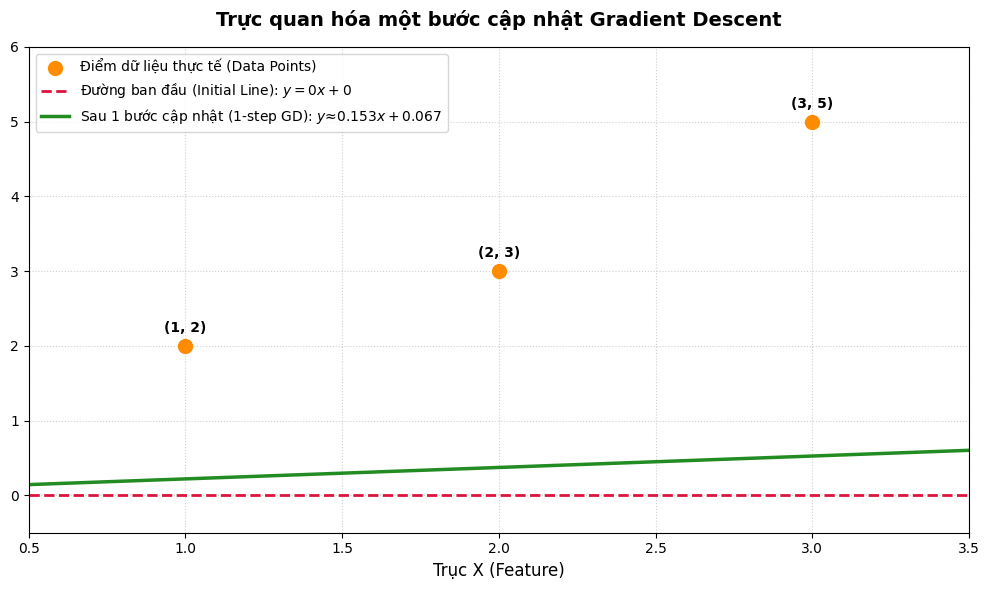

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Định nghĩa tập dữ liệu
x_data = np.array([1, 2, 3])
y_data = np.array([2, 3, 5])

# 2. Định nghĩa các đường thẳng
# Đường thẳng ban đầu: y = 0x + 0
m_initial, b_initial = 0.0, 0.0
# Đường thẳng sau 1 bước Gradient Descent: y = 0.153x + 0.067
m_new, b_new = 0.153, 0.067

# Tạo các điểm x để vẽ đồ thị đường thẳng mượt mà hơn
x_line = np.linspace(0.5, 3.5, 100)
y_line_initial = m_initial * x_line + b_initial
y_line_new = m_new * x_line + b_new

# 3. Vẽ biểu đồ
plt.figure(figsize=(10, 6), dpi=100)

# Vẽ các điểm dữ liệu thực tế (Scatter plot)
plt.scatter(x_data, y_data, color='darkorange', s=100, zorder=5, label='Điểm dữ liệu thực tế (Data Points)')

# Vẽ đường thẳng ban đầu (m=0, b=0)
plt.plot(x_line, y_line_initial, color='crimson', linestyle='--', linewidth=2,
         label='Đường ban đầu (Initial Line): $y = 0x + 0$')

# Vẽ đường thẳng sau 1 bước cập nhật (m=0.153, b=0.067)
plt.plot(x_line, y_line_new, color='forestgreen', linestyle='-', linewidth=2.5,
         label=r'Sau 1 bước cập nhật (1-step GD): $y ≈ 0.153x + 0.067$')

# Thêm chú thích cho từng điểm dữ liệu cụ thể để người học dễ theo dõi
for x, y in zip(x_data, y_data):
    plt.annotate(f'({x}, {y})', (x, y), textcoords="offset points", xytext=(0,10), ha='center', fontsize=10, fontweight='bold')

# Thiết lập tiêu đề và nhãn
plt.title('Trực quan hóa một bước cập nhật Gradient Descent', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Trục X (Feature)', fontsize=12)

# Thiết lập giới hạn trục và hiển thị lưới tọa độ rõ ràng
plt.xlim(0.5, 3.5)
plt.ylim(-0.5, 6.0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', fontsize=10)

# Hiển thị biểu đồ
plt.tight_layout()
plt.show()